# MOXSI Flux Predictions for Calibration at GSFC Beamline

In [1]:
import pathlib

import astropy.coordinates
import astropy.table
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
import sunpy.coordinates

from astropy.visualization import quantity_support
from scipy.integrate import simpson
from scipy.interpolate import interp1d
from scipy.io import readsav

from mocksipipeline.instrument.configuration import moxsi_built_spectrogram_pinhole, moxsi_built_spectrogram_slot

## GSFC Beamline Targets

Athiray fit a model to the beamline spectra that we got and isolated the continuum and several of the strongest lines. Below, I've loaded the spectra of those strongest lines.

In [2]:
# Currents used when taking data for each target. I'm not sure where these numbers come from
beamline_currents = {
    'Al': 15 * u.milliampere,
    'Fe': 10 * u.milliampere,
    'Ti': 10 * u.milliampere,
}
line_labels = {
    'Al': ['Mg Ka', 'Al Ka', 'Si Ka'],
    'Fe': ['Si Ka', 'Fe Ka', 'Fe Kb'],
    'Ti': ['Si Ka', 'Ti Ka', 'Ti Kb'],
}

In [3]:
flux_unit = u.Unit('ph / (s cm2 keV)')
tables = {}
for filename in sorted(pathlib.Path('data').glob('*_target_model.txt')):
    tab = astropy.table.QTable.read(filename, format='ascii.no_header', data_start=2)
    tab.rename_column('col1', 'Energy')
    tab.rename_column('col2', 'Continuum')
    tab['Energy'].unit = 'keV'
    tab['Continuum'].unit = flux_unit
    target = filename.name.split('_')[0]
    for i in range(len(tab.columns)-2):
        tab.rename_column(f'col{i+3}', line_labels[target][i])
        tab[line_labels[target][i]].unit = flux_unit
    tab['Target'] = tab['Energy'].shape[0]*[target,]
    tab['Wavelength'] = tab['Energy'].to('Angstrom', equivalencies=u.spectral())
    tables[target] = tab[['Target', 'Energy', 'Wavelength', 'Continuum']+tab.colnames[2:-2]]

In [4]:
tables['Al']

Target,Energy,Wavelength,Continuum,Mg Ka,Al Ka,Si Ka
,keV,Angstrom,ph / (keV s cm2),ph / (keV s cm2),ph / (keV s cm2),ph / (keV s cm2)
str2,float64,float64,float64,float64,float64,float64
Al,1.0011961,12.383607810018459,5603.4475,0.71723863,2.3179491e-24,1.1015448e-45
Al,1.0146445,12.219471788710258,5574.7369,1.8591387,9.2284261e-23,5.1143126e-44
Al,1.0280927,12.059632213437585,5546.3877,4.5910835,3.3184425e-21,2.2266231e-42
Al,1.041541,11.903919138392078,5518.3896,10.797353,1.0774025e-19,9.0873056e-41
Al,1.0549892,11.752177030172463,5490.7329,24.176705,3.1574581e-18,3.4756136e-39
Al,1.0684375,11.604253728758138,5463.408,51.528494,8.3503763e-17,1.2454567e-37
Al,1.0818857,11.460008985533337,5436.4062,104.27636,1.9879289e-15,4.1710375e-36
Al,1.0953339,11.319306234674217,5409.7187,200.76282,4.2686732e-14,1.3081237e-34


(1.0, 10.0)

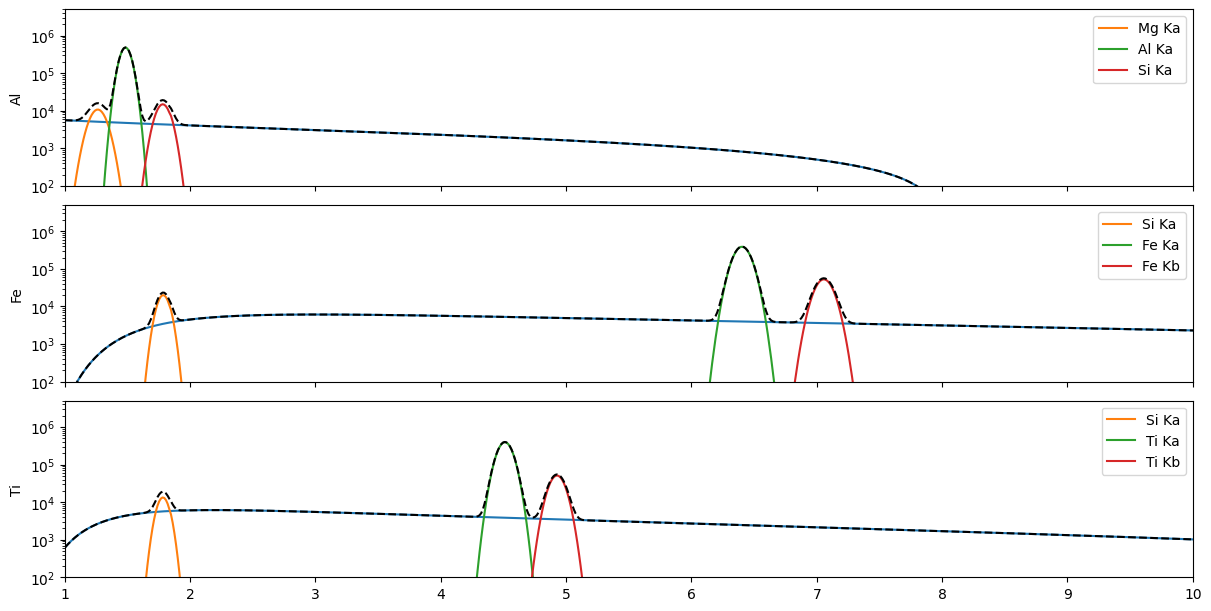

In [5]:
fig,axes = plt.subplots(3,1,figsize=(12,6), layout='constrained',sharex=True, sharey=True)
for i,k in enumerate(tables):
    ax = axes[i]
    ax.plot(tables[k]['Energy'], tables[k]['Continuum'])
    tot = tables[k]['Continuum']
    for col in tables[k].colnames[4:]:
        ax.plot(tables[k]['Energy'], tables[k][col], label=col)
        tot += tables[k][col]
    ax.plot(tables[k]['Energy'], tot, color='k', ls='--')
    ax.set_yscale('log')
    ax.set_ylim(1e2,5e6)
    ax.set_ylabel(tables[k]['Target'][0])
    ax.label_outer()
    ax.legend()
ax.set_xlim(1,10)

## Convolution of MOXSI Effective Area with GSFC Targets

In [6]:
moxsi_responses = [
    moxsi_built_spectrogram_pinhole[12],
    moxsi_built_spectrogram_pinhole[13],
    moxsi_built_spectrogram_pinhole[14],
    moxsi_built_spectrogram_slot[12],
    moxsi_built_spectrogram_slot[13],
    moxsi_built_spectrogram_slot[14],
]

In [7]:
target_table = {
    'target': [],
    'line': [],
    'energy': [],
    'wavelength': [],
    'flux': [],
}
for mr in moxsi_responses:
    target_table[f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'] = []
for target_name in tables:
    tab = tables[target_name]
    for i,line_name in enumerate(tab.colnames[4:]):
        target_table['line'].append(line_name)
        target_table['target'].append(tab['Target'][0])
        target_table['energy'].append(tab['Energy'][np.argmax(tab[line_name])])
        target_table['flux'].append(
            simpson(tab[line_name].to_value('ph / (cm2 s keV)'),
                    x=tab['Energy'].to_value('keV')) * u.Unit('ph / (cm2 s)')
        )
        for mr in moxsi_responses:
            ea_interp = np.interp(tab['Energy'], mr.energy[::-1], mr.effective_area[::-1])
            flux_moxsi = simpson(
                (tab[line_name]*ea_interp).to_value('ph s-1 keV-1'),
                x=tab['Energy'].to_value('keV')
            ) * u.Unit('ph / s')
            flux_moxsi = flux_moxsi / beamline_currents[target_name]
            target_table[f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'].append(flux_moxsi)
target_table['energy'] = u.Quantity(target_table['energy'])
target_table['wavelength'] = target_table['energy'].to('AA', equivalencies=u.equivalencies.spectral())
target_table['flux'] = u.Quantity(target_table['flux'])
for mr in moxsi_responses:
    colname = f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'
    target_table[colname] = u.Quantity(target_table[colname])
target_table = astropy.table.QTable(target_table)

/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtb

In [8]:
target_table

target,line,energy,wavelength,flux,moxsi_pinhole_1,moxsi_pinhole_2,moxsi_pinhole_3,moxsi_slot_1,moxsi_slot_2,moxsi_slot_3
,,keV,Angstrom,ph / (s cm2),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s)
str2,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64
Al,Mg Ka,1.2701612,9.761296316813981,1615.88953473551,9.048606287913738e-05,1.4489303493411325e-05,7.73756570244082e-06,0.0009048606287913736,0.00014489303493411327,7.73756570244082e-05
Al,Al Ka,1.4853332,8.347231343997445,50192.263189542085,0.003667933961604005,0.00043535950593789126,0.00030543392495140255,0.03667933961604006,0.004353595059378912,0.003054339249514025
Al,Si Ka,1.7811947,6.960732503482086,1960.3847971750668,0.00016168179779408562,1.3724942909644272e-05,1.2129035434970715e-05,0.0016168179779408561,0.00013724942909644274,0.00012129035434970714
Fe,Si Ka,1.7811947,6.960732503482086,2243.126199336799,0.00027058667783113444,2.2944074056281936e-05,2.0294402834874808e-05,0.0027058667783113445,0.00022944074056281935,0.00020294402834874814
Fe,Fe Ka,6.4073925,1.9350180035513702,61246.831287473426,0.0019251198982084814,0.00010856602980837882,0.00011850382052470344,0.01925119898208481,0.001085660298083788,0.0011850382052470344
Fe,Fe Kb,7.0529084,1.7579159036462213,8603.048743941104,0.00018511285187613108,1.0277238783783667e-05,1.1365566582120325e-05,0.0018511285187613109,0.00010277238783783665,0.00011365566582120323
Ti,Si Ka,1.7811947,6.960732503482086,1445.0407633519098,0.00017134419780238458,1.457057728907963e-05,1.2866442731512764e-05,0.0017134419780238455,0.00014570577289079633,0.00012866442731512763
Ti,Ti Ka,4.511189,2.7483707384727234,54490.16623816875,0.005084769776638842,0.0003168392866632333,0.00031510412247652607,0.050847697766388436,0.003168392866632333,0.003151041224765261


This now cuts the targets down to only the three strongest lines

In [9]:
target_table = target_table[[1,4,7]]

In [10]:
target_table

target,line,energy,wavelength,flux,moxsi_pinhole_1,moxsi_pinhole_2,moxsi_pinhole_3,moxsi_slot_1,moxsi_slot_2,moxsi_slot_3
,,keV,Angstrom,ph / (s cm2),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s),ph / (mA s)
str2,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64
Al,Al Ka,1.4853332,8.347231343997445,50192.263189542085,0.003667933961604005,0.00043535950593789126,0.00030543392495140255,0.03667933961604006,0.004353595059378912,0.003054339249514025
Fe,Fe Ka,6.4073925,1.9350180035513702,61246.831287473426,0.0019251198982084814,0.00010856602980837882,0.00011850382052470344,0.01925119898208481,0.001085660298083788,0.0011850382052470344
Ti,Ti Ka,4.511189,2.7483707384727234,54490.16623816875,0.005084769776638842,0.0003168392866632333,0.00031510412247652607,0.050847697766388436,0.003168392866632333,0.003151041224765261


In [11]:
integration_times = np.arange(1,1e6,1)*u.s
beam_currents = [15, 30, 50, 100, 150, 200, 250, 300] * u.milliampere
photon_threshold = 1000 * u.photon
rate_limit = 10 * u.photon / u.s

In [12]:
integration_time_table = {}
for mr in moxsi_responses:
    colname = f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'
    needed_int_times = []
    for mpps in target_table[colname]:
        rates = mpps * beam_currents
        is_above_threshold = np.outer(rates, integration_times) > photon_threshold
        _needed_int_times = u.Quantity([integration_times[x][0] if x.any() else np.inf*u.s for x in is_above_threshold])
        _needed_int_times = np.where(rates>rate_limit, np.nan, _needed_int_times)
        needed_int_times.append(_needed_int_times)
    integration_time_table[colname] = u.Quantity(needed_int_times).to('h')
integration_time_table = astropy.table.hstack([
    target_table[['line', 'target', 'energy', 'wavelength']],
    astropy.table.QTable({'current': np.tile(beam_currents,(len(target_table),1))}),
    astropy.table.QTable(integration_time_table)
])

This table shows the needed integration times to meet threshold for different MOXSI responses and beam currents. In cases where the rates exceed 10 ph/s, the integration times are marked as NaN to indicate these particular current settings should not be used.

In [13]:
integration_time_table

line,target,energy,wavelength,current,moxsi_pinhole_1,moxsi_pinhole_2,moxsi_pinhole_3,moxsi_slot_1,moxsi_slot_2,moxsi_slot_3
,,keV,Angstrom,mA,h,h,h,h,h,h
str5,str2,float64,float64,float64[8],float64[8],float64[8],float64[8],float64[8],float64[8],float64[8]
Al Ka,Al,1.4853332,8.347231343997445,15.0 .. 300.0,5.0488888888888885 .. 0.2525,42.53638888888889 .. 2.1269444444444443,60.63027777777778 .. 3.0316666666666667,0.505 .. nan,4.253888888888889 .. 0.2127777777777778,6.063055555555556 .. 0.30333333333333334
Fe Ka,Fe,6.4073925,1.9350180035513702,15.0 .. 300.0,9.619444444444444 .. 0.4811111111111111,170.5738888888889 .. 8.528888888888888,156.26944444444445 .. 7.813611111111111,0.9619444444444445 .. 0.04833333333333333,17.0575 .. 0.8530555555555556,15.626944444444444 .. 0.7813888888888889
Ti Ka,Ti,4.511189,2.7483707384727234,15.0 .. 300.0,3.6422222222222222 .. 0.18222222222222223,58.44777777777778 .. 2.9225,58.76972222222222 .. 2.9386111111111113,0.36444444444444446 .. nan,5.845 .. 0.2925,5.877222222222223 .. 0.29388888888888887


Can we remake the above table that replaces each moxsi cell and the current cell by asking what is the lowest current that permits a needed integration time under 1 hour? If the answer is "None", then what is the integration time we have to deal with?

In [14]:
# Just need these things to do the wavelength mapping
obs = sunpy.coordinates.get_earth(time='2020-01-01')
source_pos = astropy.coordinates.SkyCoord(Tx=0*u.arcsec, Ty=0*u.arcsec, frame=sunpy.coordinates.Helioprojective(observer=obs))

In [15]:
# NOTE: slot and pinhole have same 0th position in the pixel x-direction and both independent of wavelength in 0th order
px_0th = moxsi_built_spectrogram_slot[11].get_wcs(obs).world_to_pixel(source_pos, 0*u.Angstrom)[0]
integration_time_threshold = 2*u.h
qual_colname = r'meets threshold?'
summary_integration_time_table = {
    'line': [],
    'target': [],
    'energy': [],
    'wavelength': [],
    'aperture': [],
    r'order': [],
    r'offset': [],
    qual_colname: [],
    r'current': [],
    'required time': [],
}
for r in integration_time_table:
    for i,mr in enumerate(moxsi_responses):
        colname = f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'
        is_under_threshold = r[colname] < integration_time_threshold
        if is_under_threshold.any():
            idx = np.nanargmax(r[colname][is_under_threshold])
            req_int_time = r[colname][is_under_threshold][idx]
            min_req_current = r['current'][is_under_threshold][idx]
            meets_req = 'Y'
        else:
            idx = np.nanargmin(r[colname])
            req_int_time = r[colname][idx]
            min_req_current = r['current'][idx]
            meets_req = 'N'
        # Compute pixel position
        delta_x = mr.get_wcs(obs).world_to_pixel(source_pos, r['wavelength'])[0]
        delta_x -= px_0th
        # Fill in table entries
        summary_integration_time_table['line'].append(r['line'])
        summary_integration_time_table['target'].append(r['target'])
        summary_integration_time_table['energy'].append(r['energy'])
        summary_integration_time_table['wavelength'].append(r['wavelength'])
        summary_integration_time_table['aperture'].append(mr.aperture.name.split('_')[0])
        summary_integration_time_table['order'].append(mr.spectral_order)
        summary_integration_time_table['offset'].append(delta_x*u.pix)
        summary_integration_time_table['current'].append(min_req_current)
        summary_integration_time_table['required time'].append(req_int_time.to('minute'))
        summary_integration_time_table[qual_colname].append(meets_req)
for col in ['energy', 'wavelength', r'current', 'required time',  r'offset']:
    summary_integration_time_table[col] = u.Quantity(summary_integration_time_table[col])
summary_integration_time_table = astropy.table.QTable(summary_integration_time_table)

  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


In [16]:
summary_integration_time_table

line,target,energy,wavelength,aperture,order,offset,meets threshold?,current,required time
,,keV,Angstrom,,,pix,,mA,min
str5,str2,float64,float64,str8,int64,float64,str1,float64,float64
Al Ka,Al,1.4853332,8.347231343997445,circular,1,116.26500800567874,Y,50.0,90.88333333333334
Al Ka,Al,1.4853332,8.347231343997445,circular,2,232.53001601135747,N,300.0,127.61666666666666
Al Ka,Al,1.4853332,8.347231343997445,circular,3,348.7950240170362,N,300.0,181.9
Al Ka,Al,1.4853332,8.347231343997445,slot,1,116.26500800567874,Y,15.0,30.3
Al Ka,Al,1.4853332,8.347231343997445,slot,2,232.53001601135747,Y,50.0,76.56666666666668
Al Ka,Al,1.4853332,8.347231343997445,slot,3,348.7950240170362,Y,50.0,109.14999999999999
Fe Ka,Fe,6.4073925,1.9350180035513702,circular,1,26.952036478036916,Y,100.0,86.58333333333333
Fe Ka,Fe,6.4073925,1.9350180035513702,circular,2,53.90407295607383,N,300.0,511.7333333333333


In [17]:
import sys
import io
with io.StringIO() as _f:
    summary_integration_time_table.write(
        _f,
        format='ascii.aastex',
        caption=f'Required currents and integration times to achieve {photon_threshold:.0f} in under {integration_time_threshold:.0f} in major spectral lines. In cases where {integration_time_threshold:.0f} is not achievable, the max current is listed along with the integration time.',
        #latexdict={'tabletype':'longtable'},
        formats={
            'wavelength':'%.3f',
            'energy':'%.3f',
            r'current': '%.0f',
            'required time': '%.0f',
            r'offset': '%.0f',
        },
        overwrite=True)
    table_string = _f.getvalue()
md_file = f"""---
title: "MOXSI Calibration Beam Currents and Integration Times"
author:
- name: Will Barnes
aastexopts: [singlecolumn]
---

\startlongtable
{table_string}
"""
with open('tables/moxsi-calibration-currents-and-integrations-major-lines.md', mode='w') as f:
    f.write(md_file)
!cd tables && pandoc --template aastex63_template.tex moxsi-calibration-currents-and-integrations-major-lines.md -o moxsi-calibration-currents-and-integrations-major-lines.pdf

<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
/var/folders/dm/lswwp9sd03z0yhf9v2nhw37r0000gq/T/ipykernel_71670/1872572763.py:34: SyntaxWarning: invalid escape sequence '\s'


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/var/folders/dm/lswwp9sd03z0yhf9v2nhw37r0000gq/T/ipykernel_71670/2704472236.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(15,5), layout='constrained')


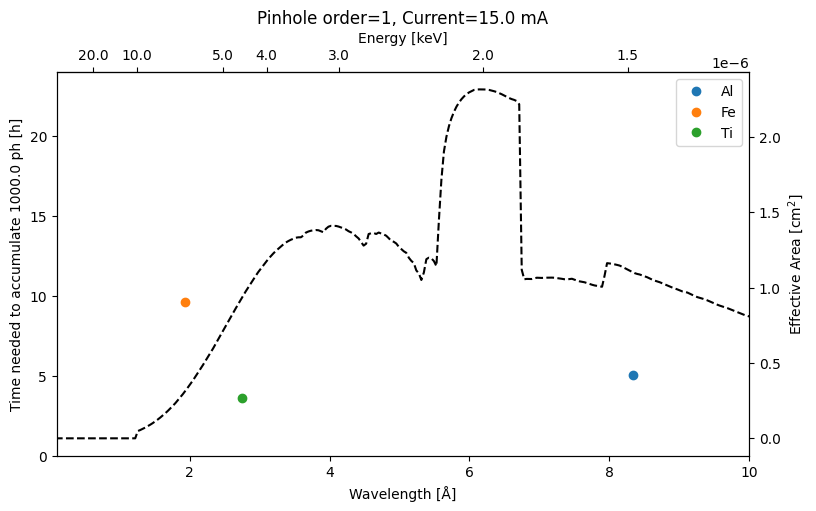

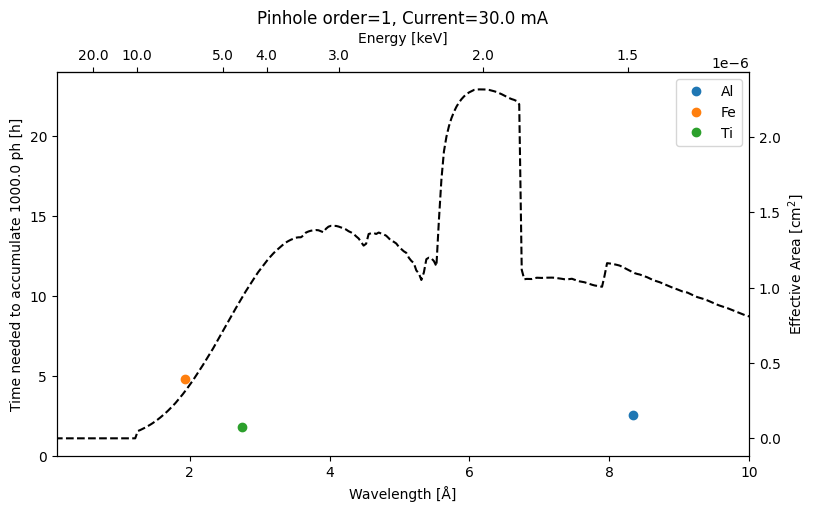

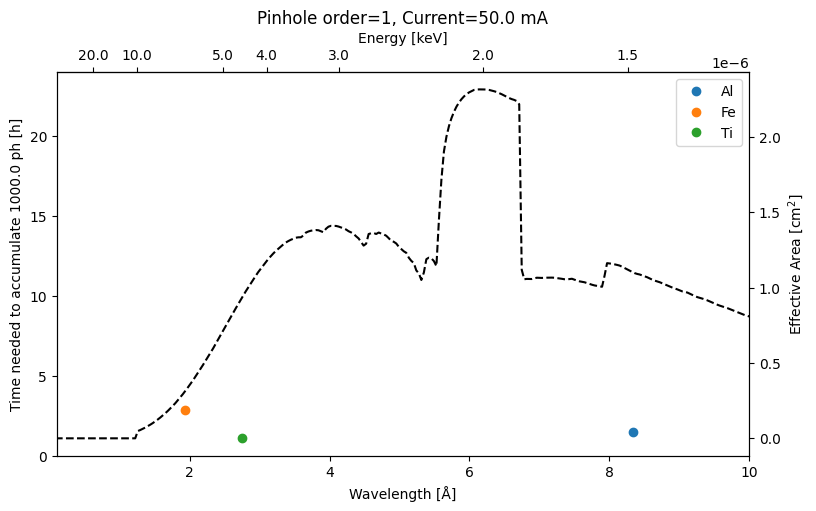

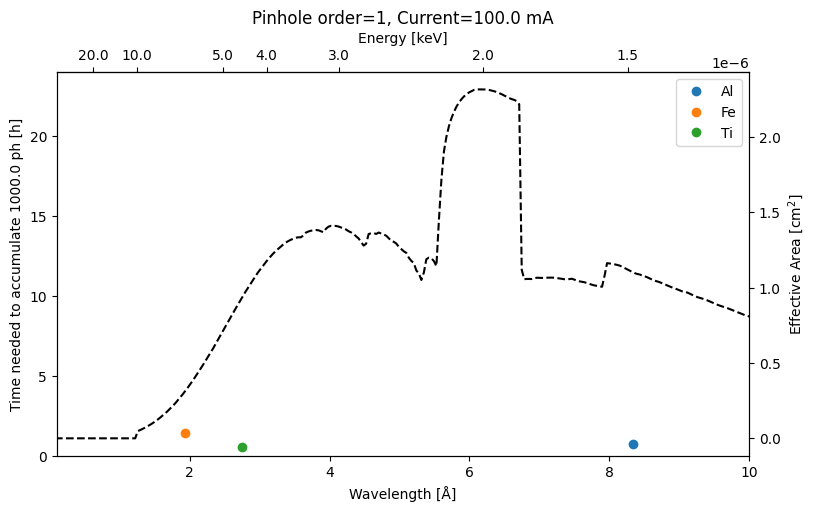

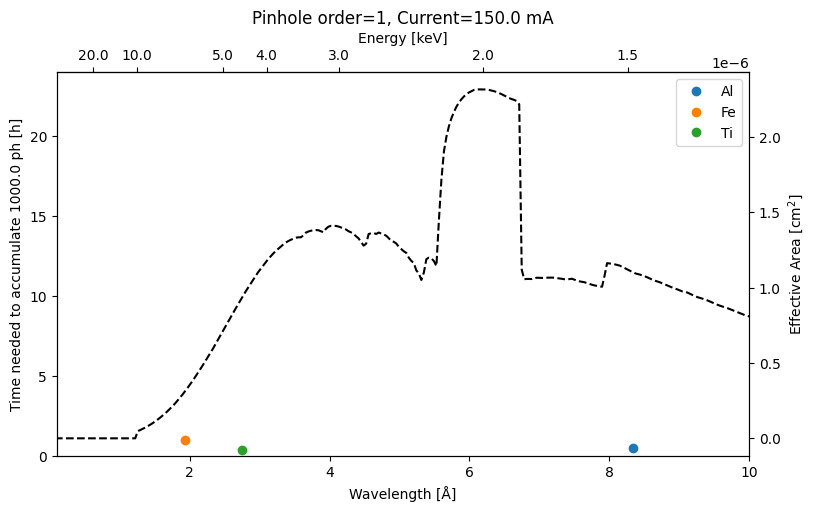

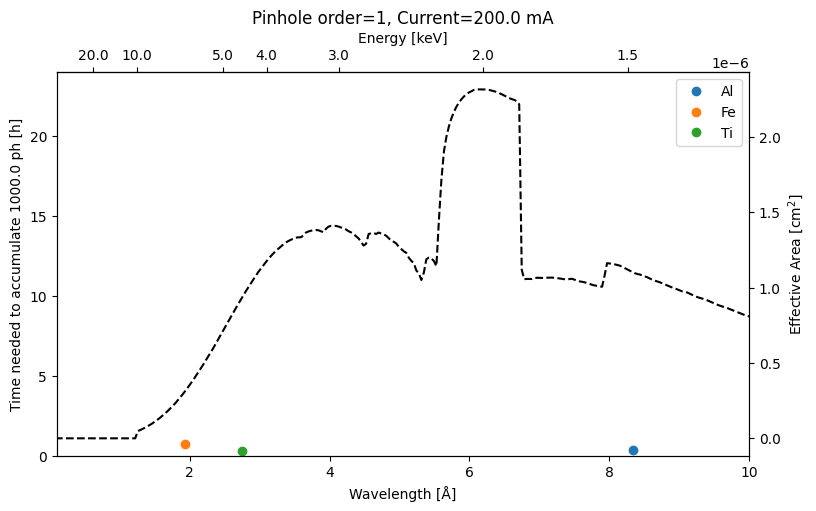

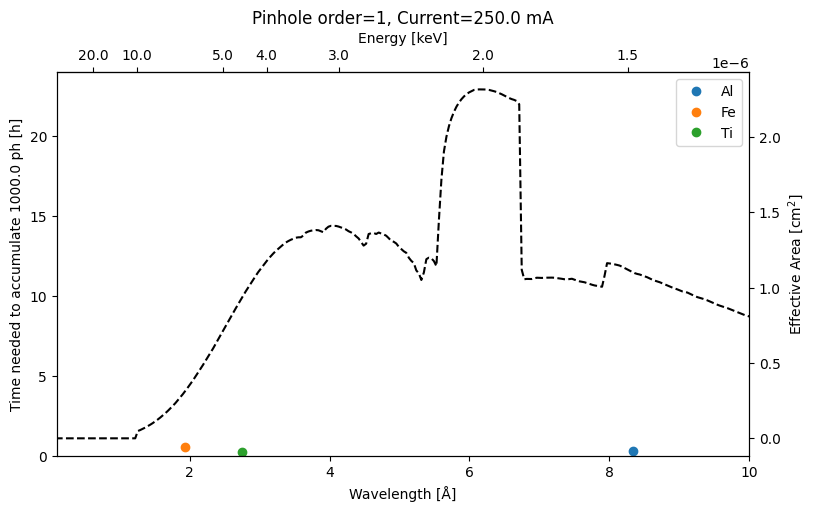

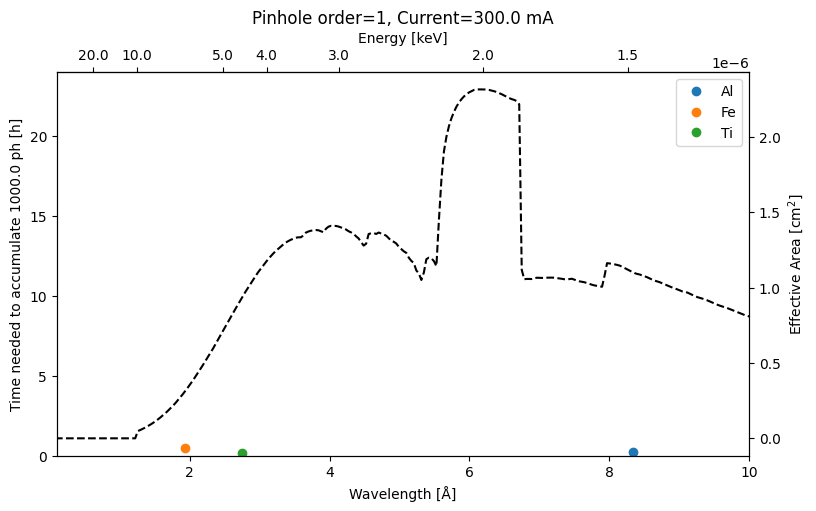

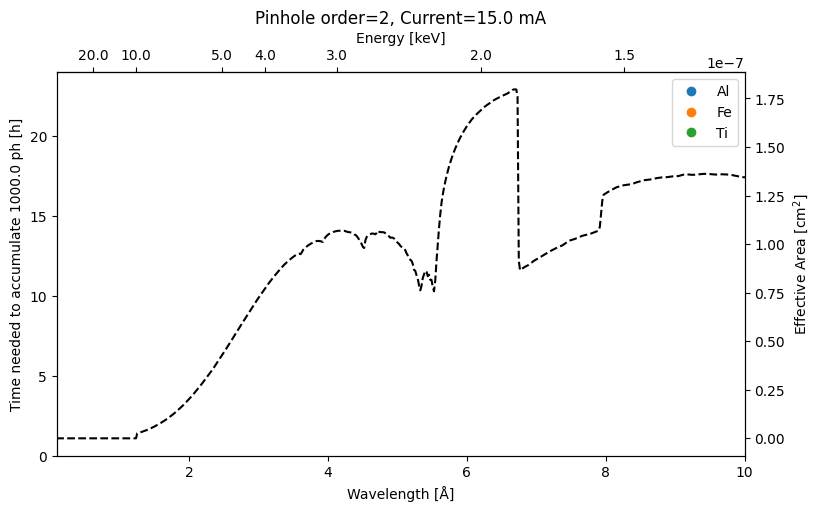

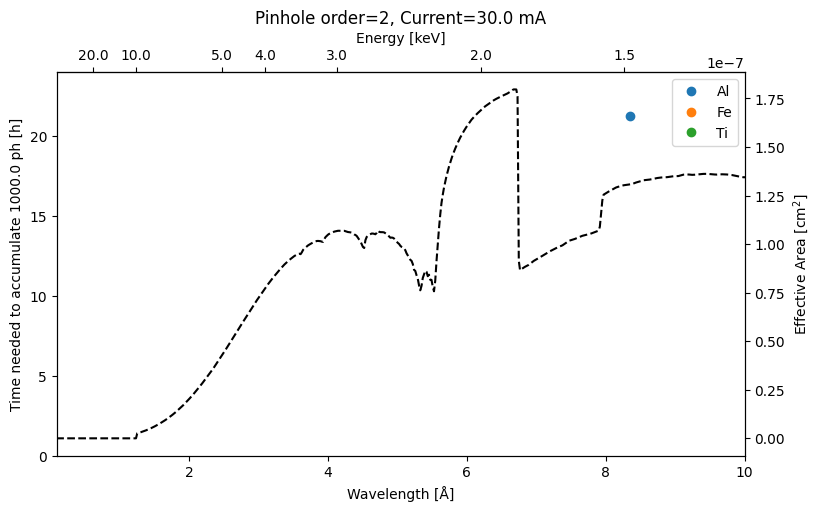

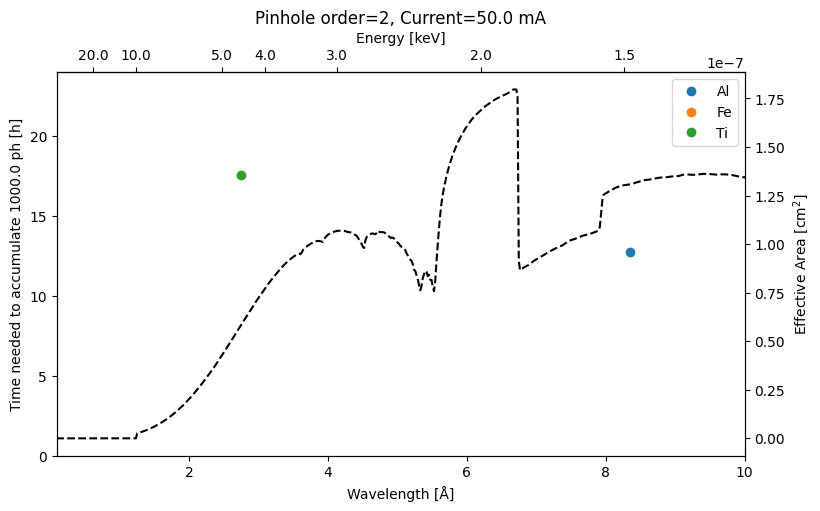

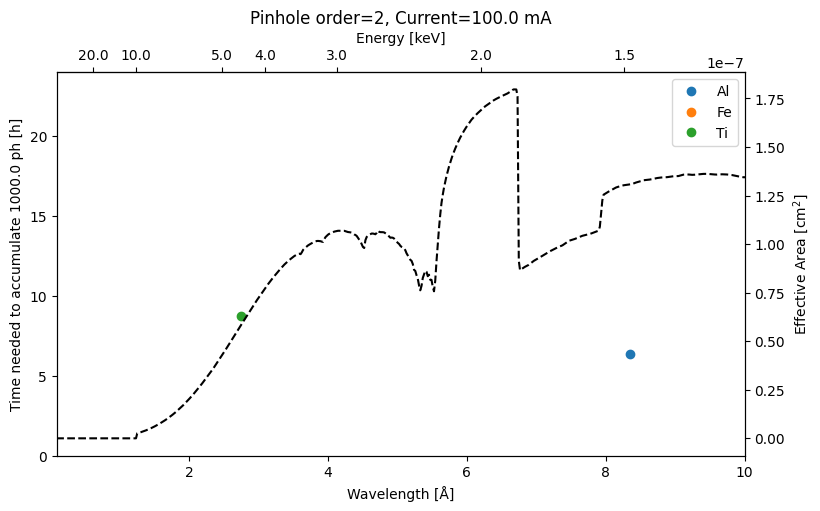

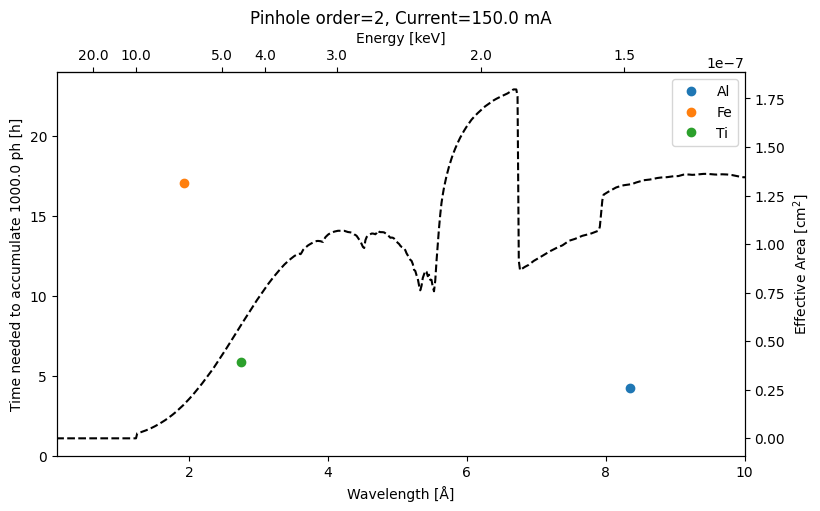

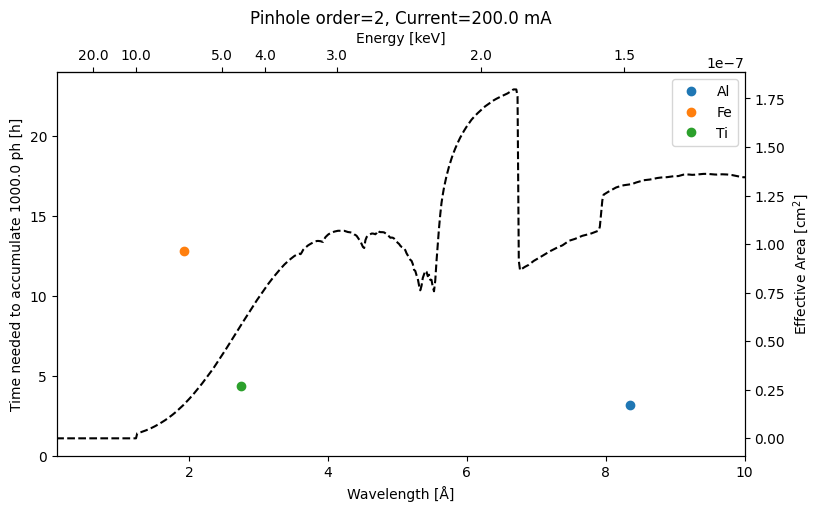

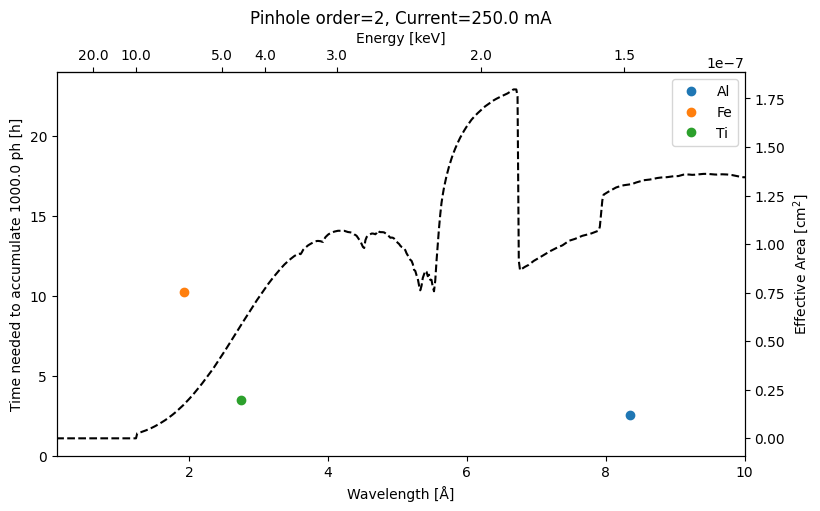

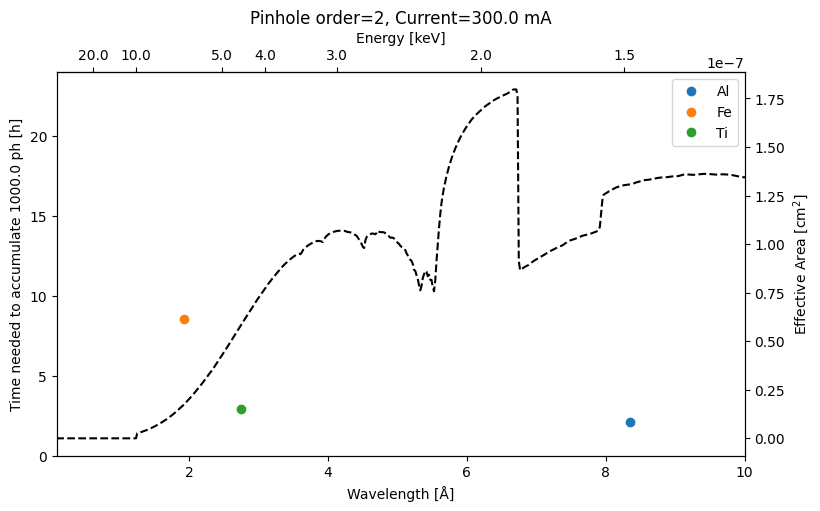

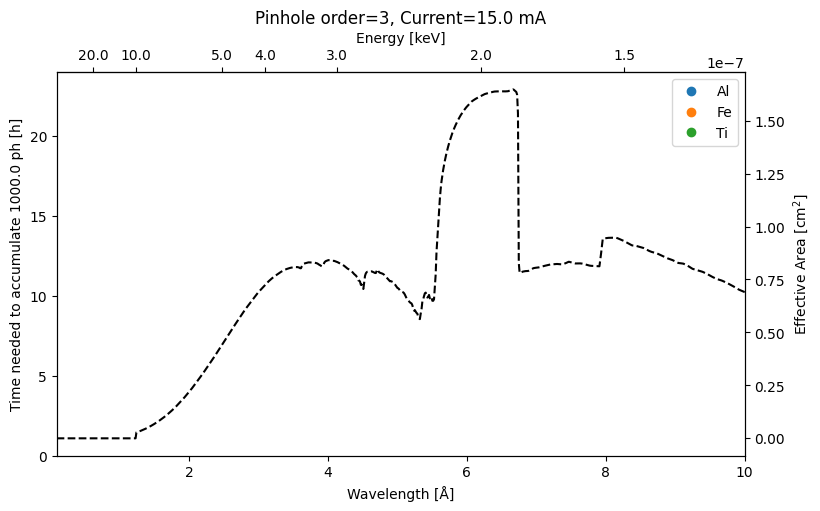

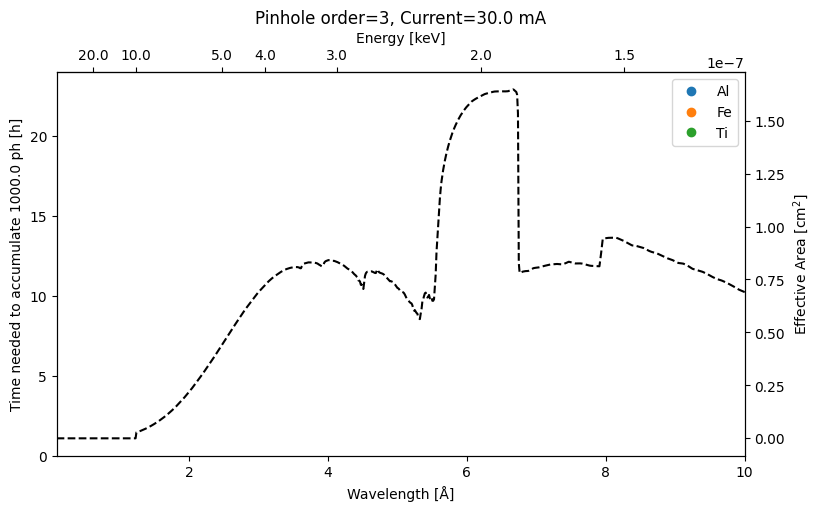

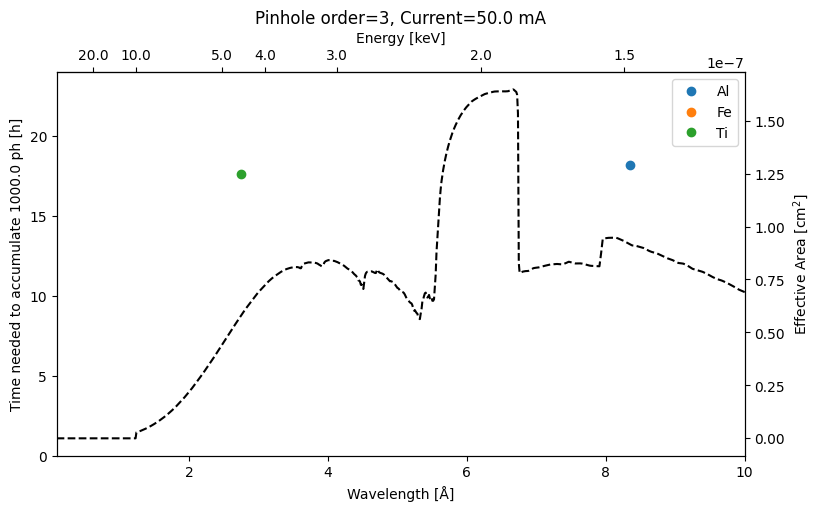

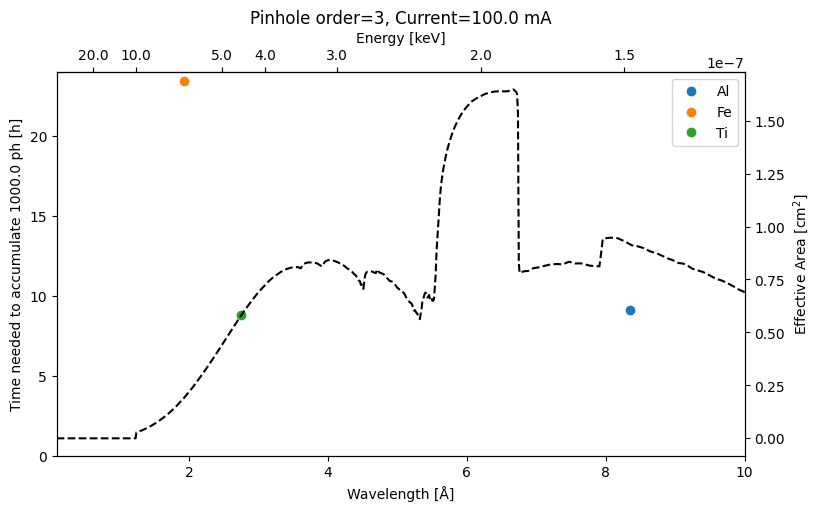

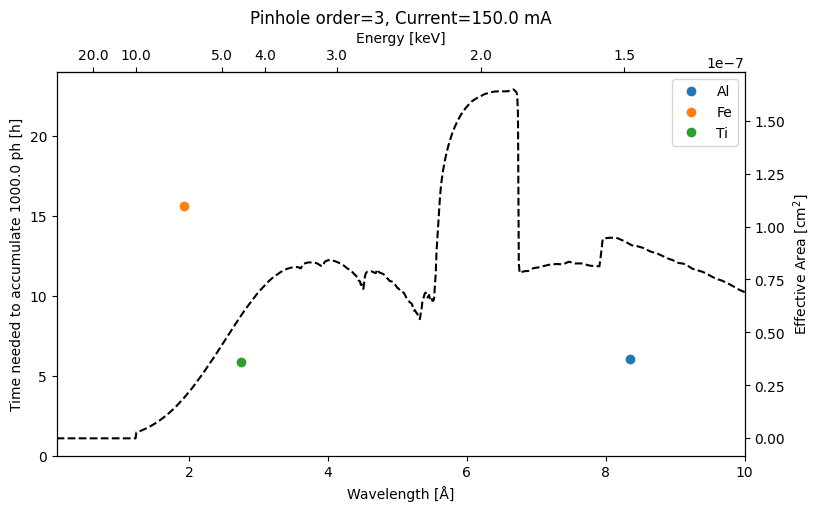

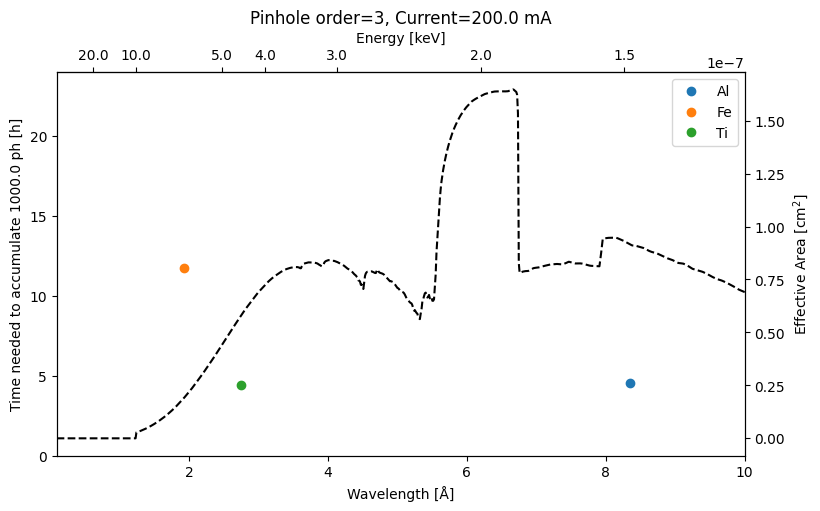

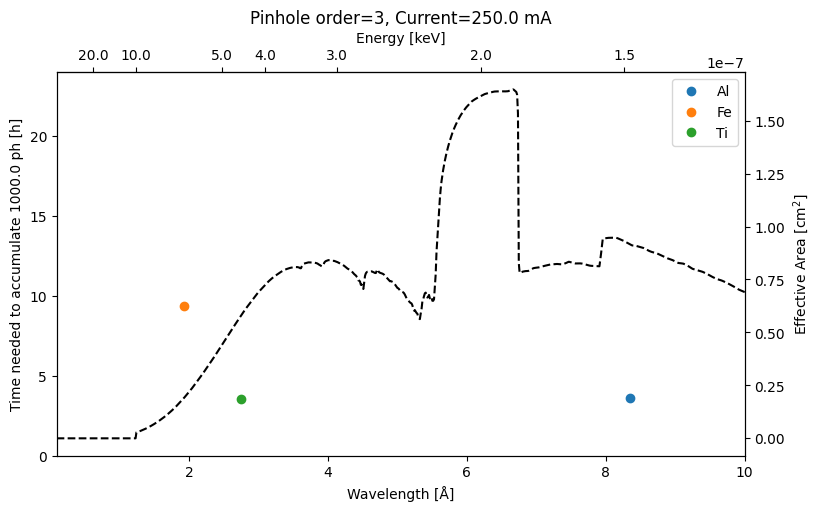

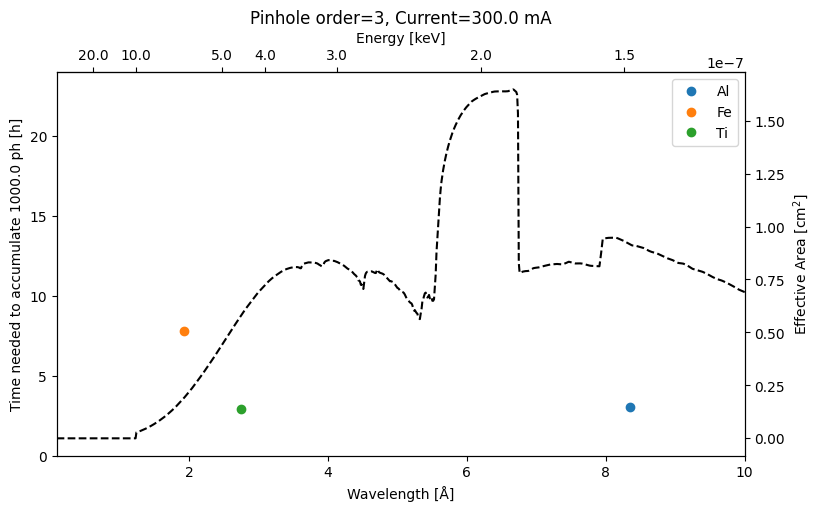

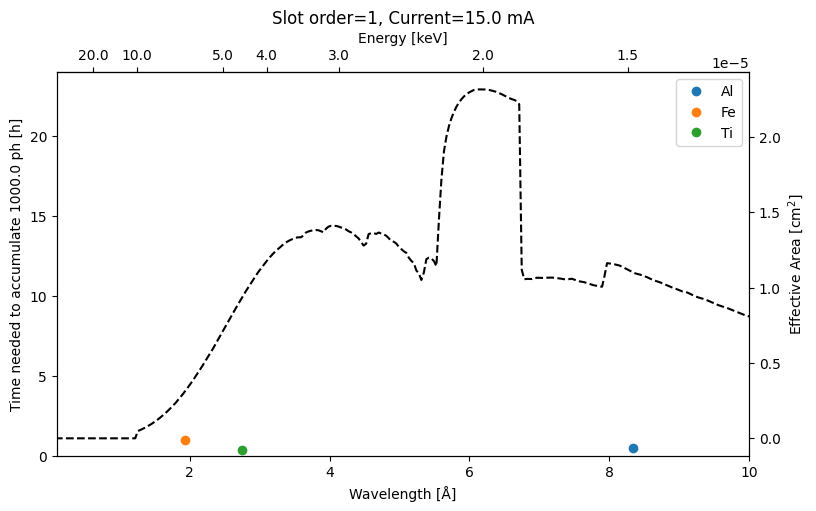

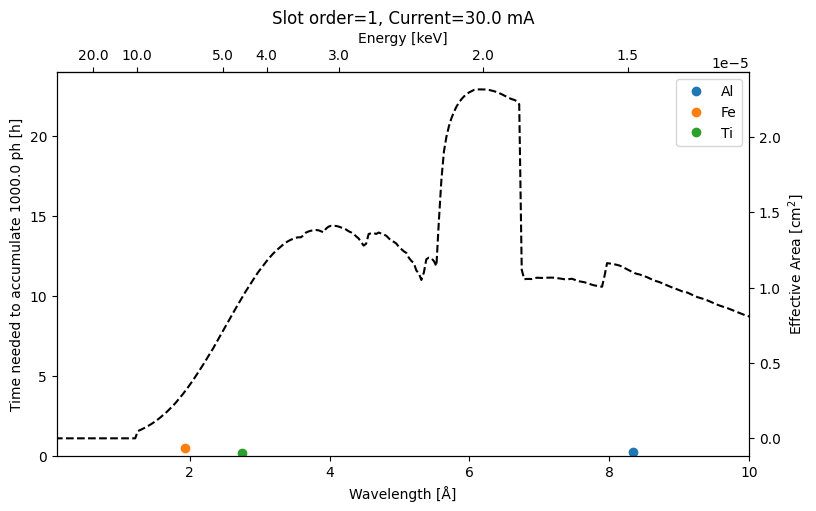

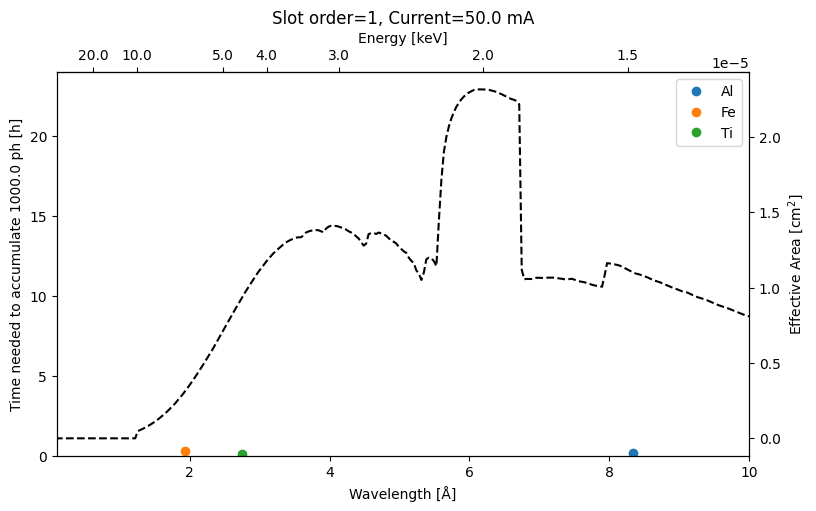

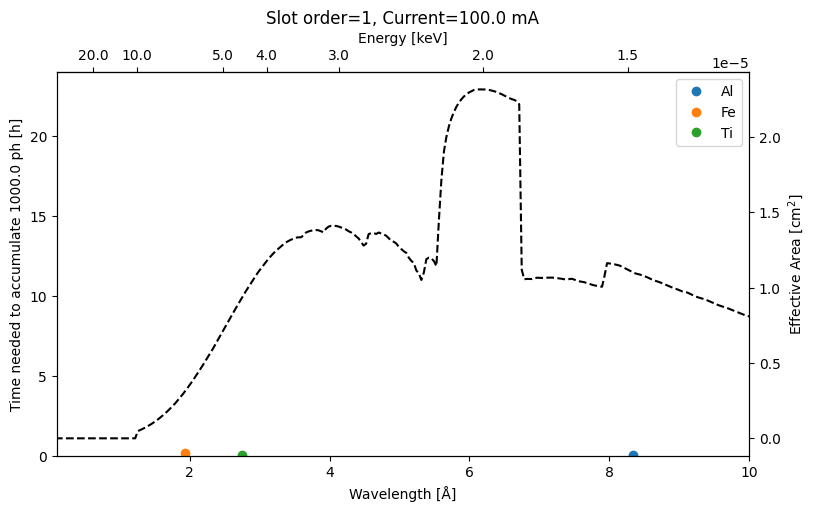

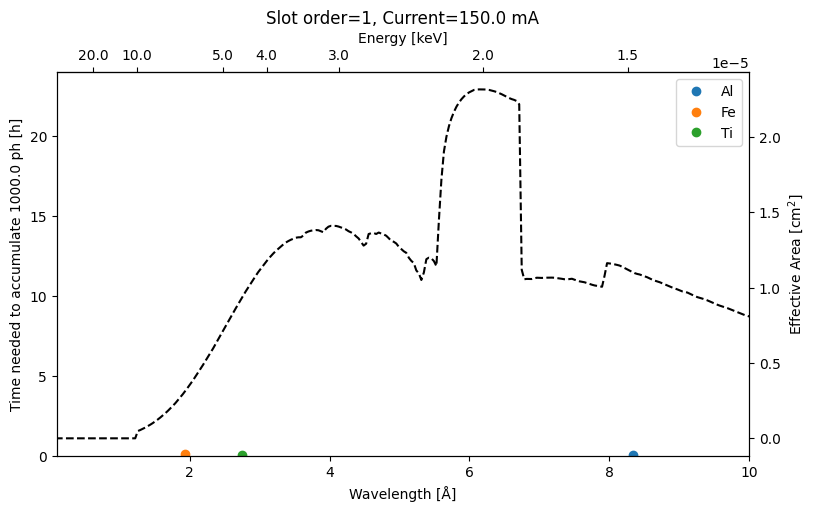

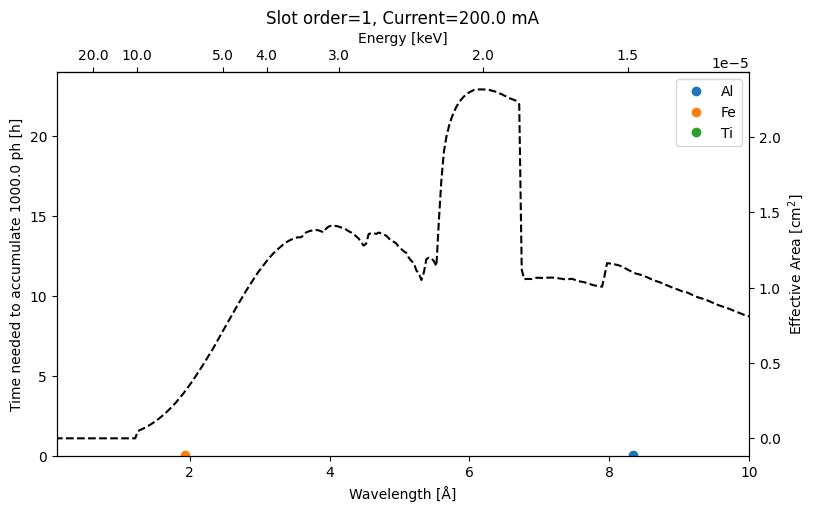

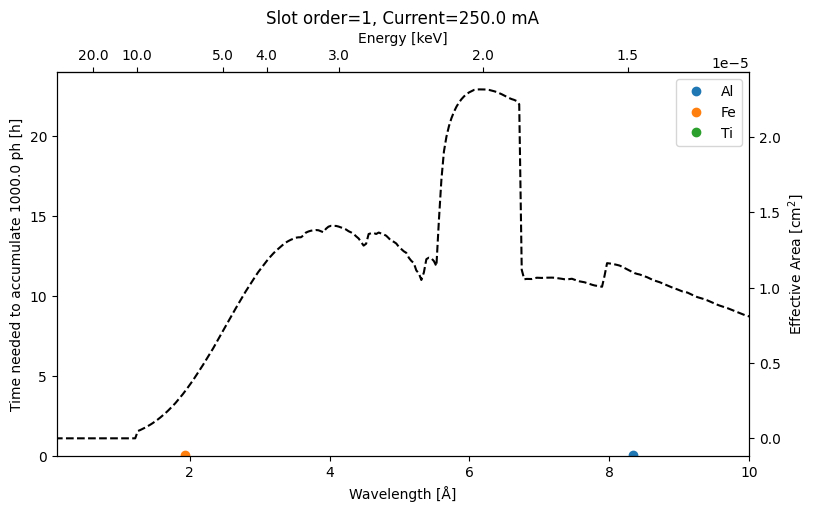

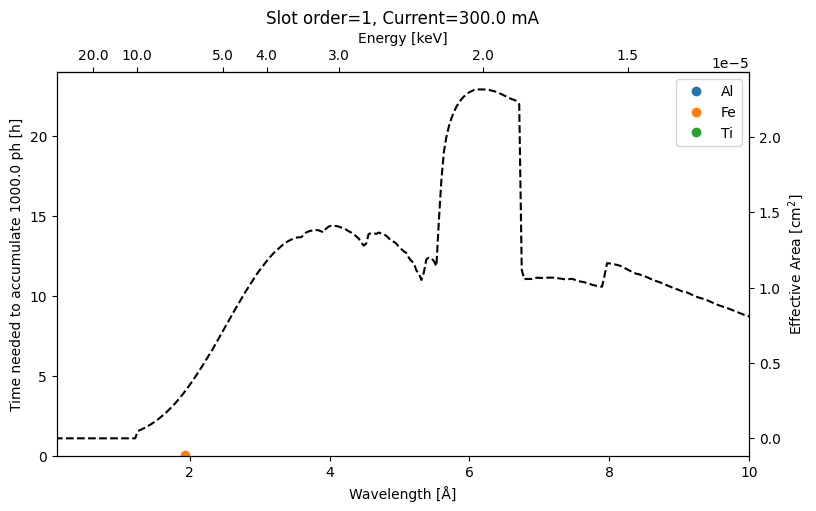

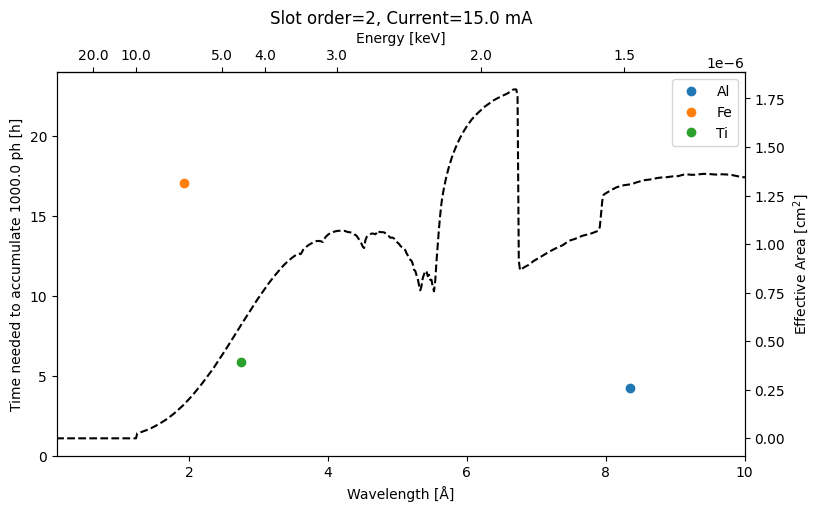

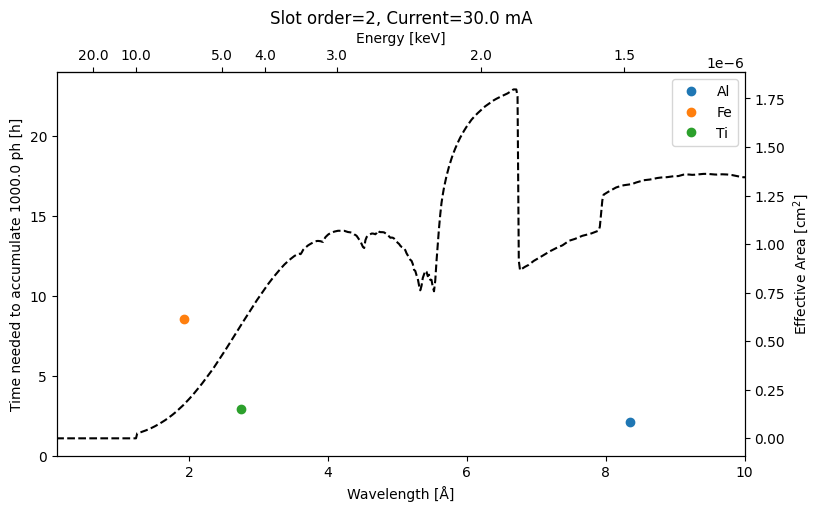

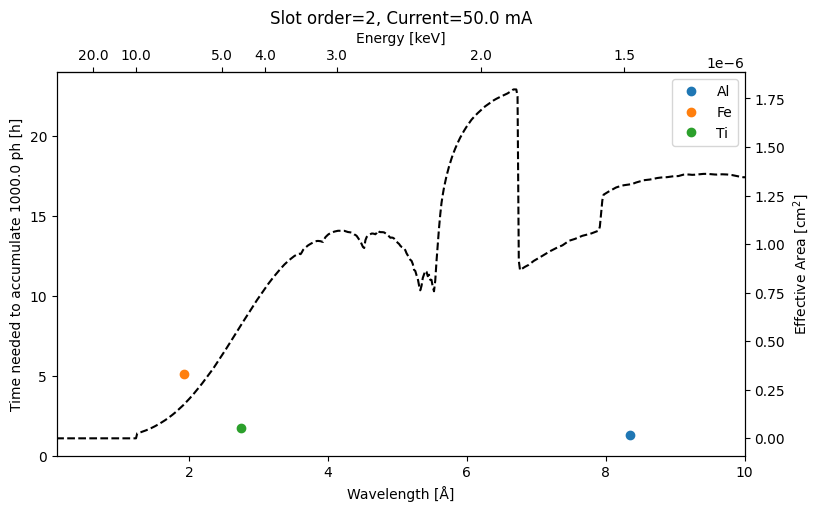

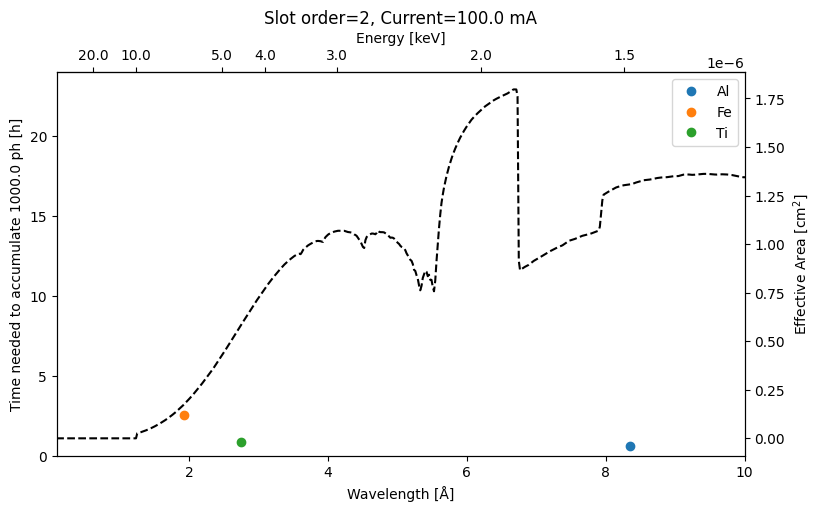

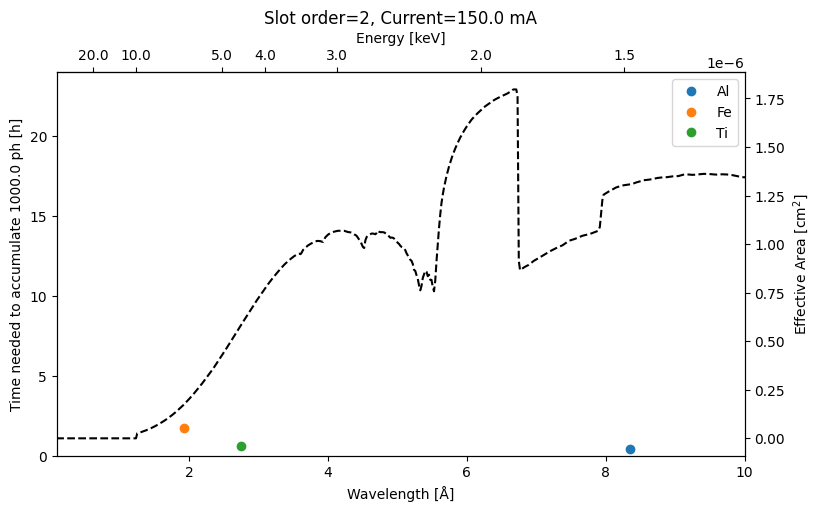

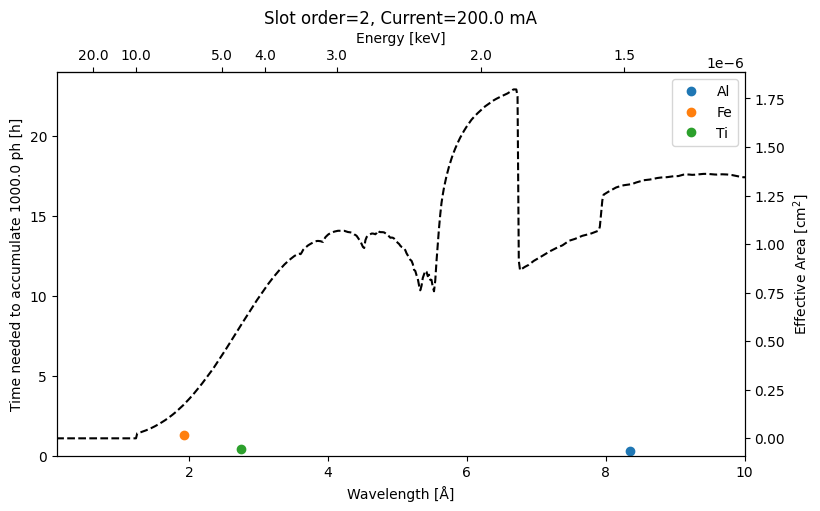

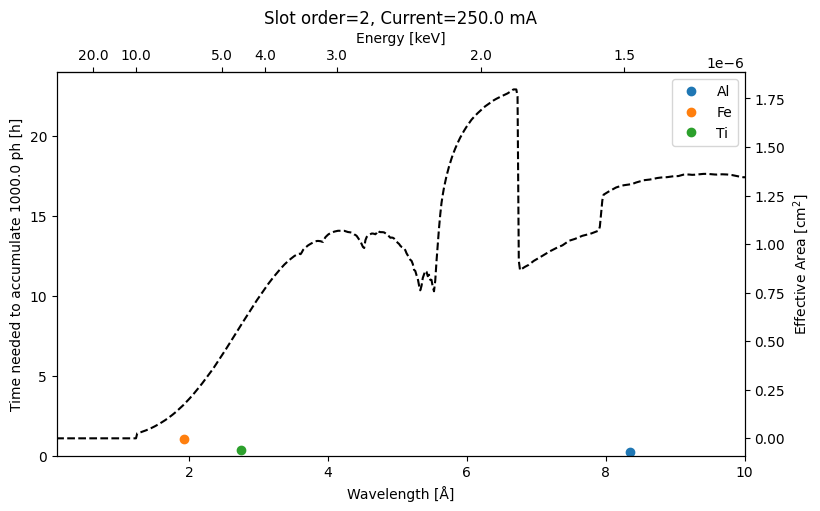

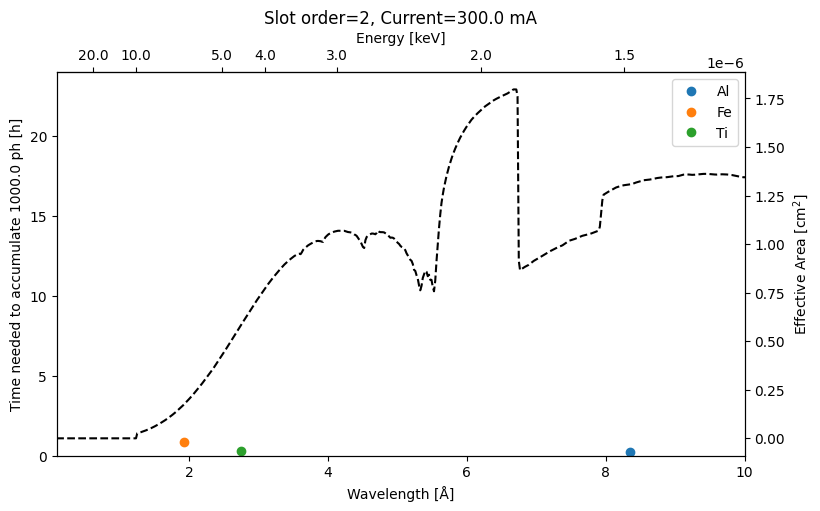

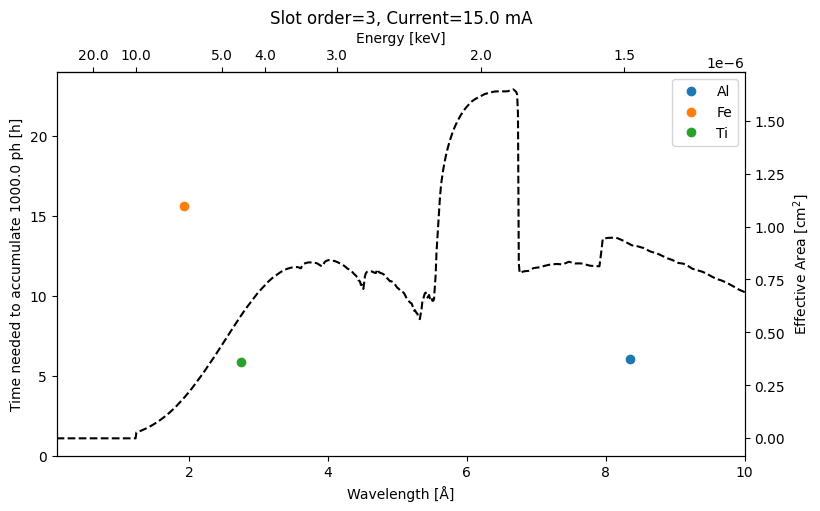

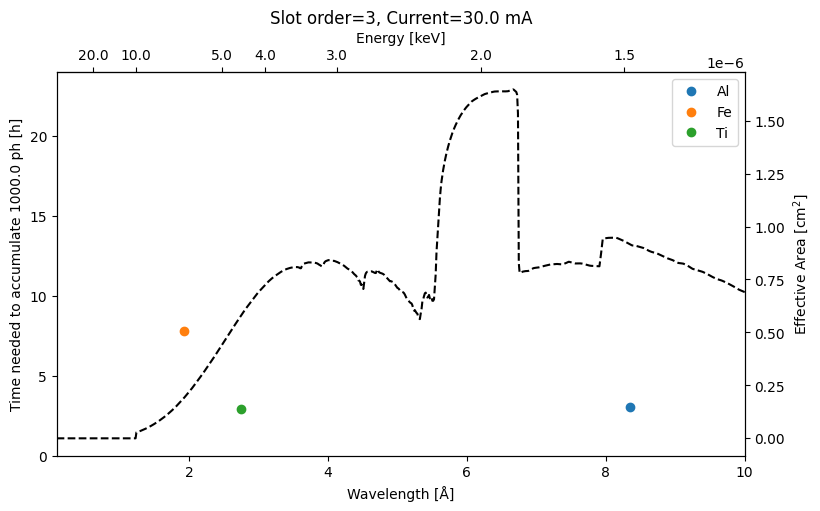

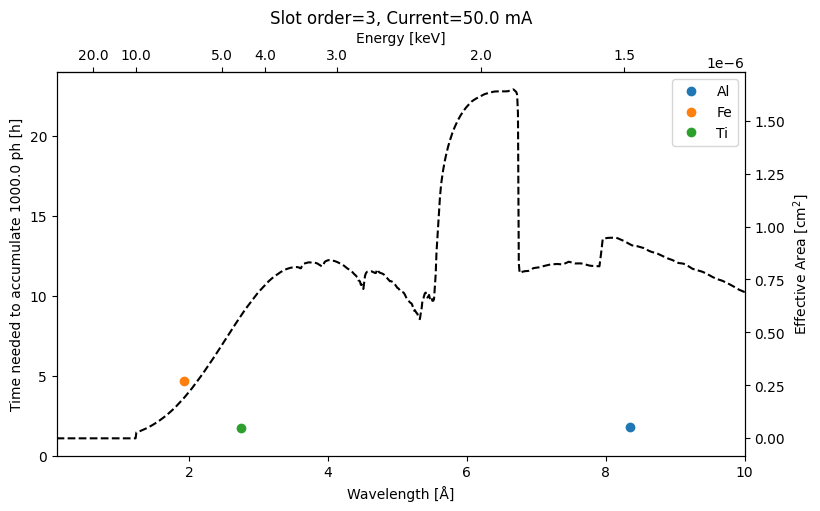

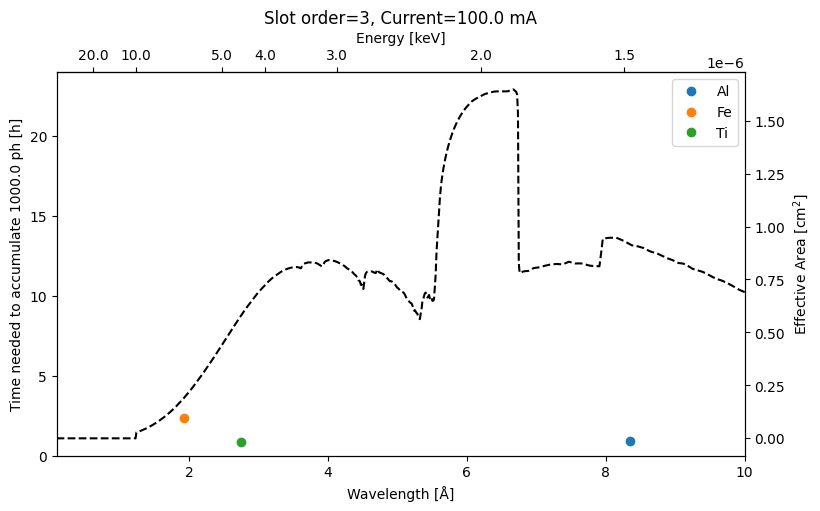

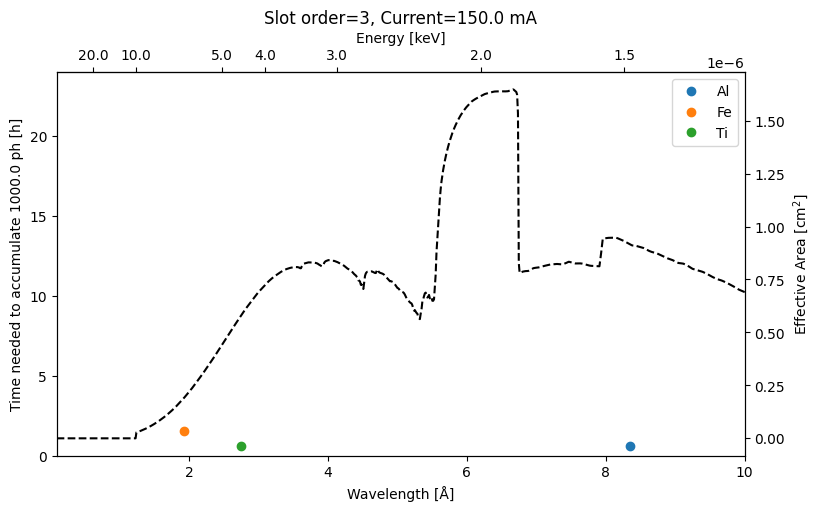

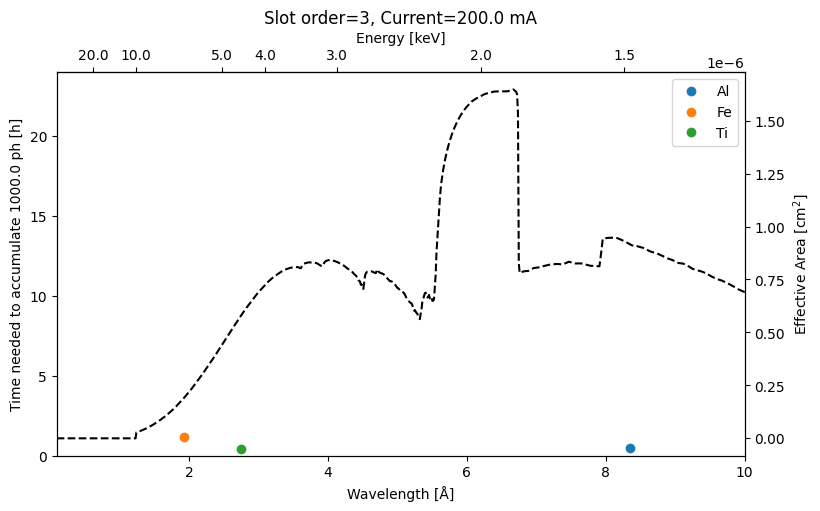

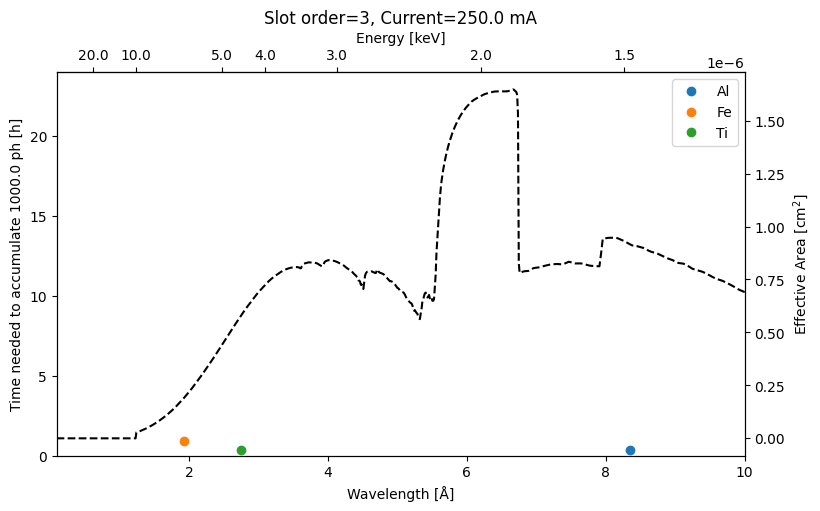

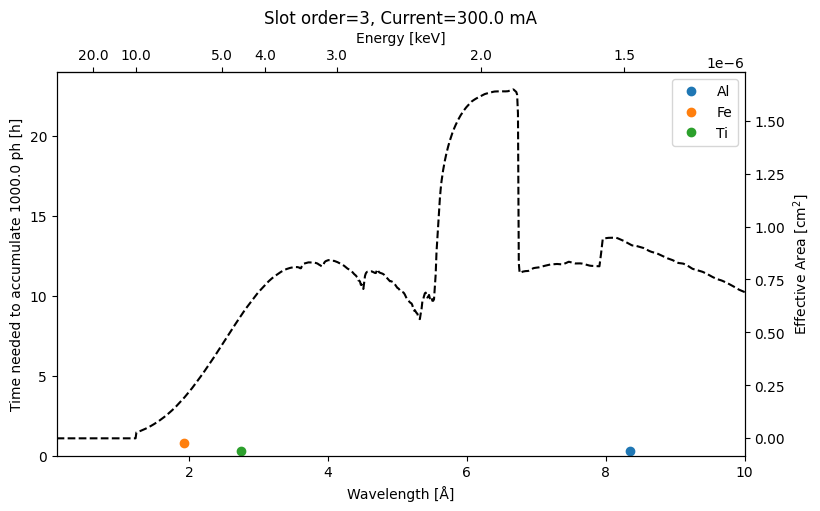

In [18]:
for mr_idx in range(len(moxsi_responses)):
    moxsi_col = integration_time_table.colnames[5+mr_idx]
    for current_idx in range(beam_currents.shape[0]):
        fig = plt.figure(figsize=(15,5), layout='constrained')
        ax = fig.add_subplot(121)
        for i,grp in enumerate(integration_time_table.group_by('target').groups):
            ax.plot(grp['wavelength'], grp[moxsi_col].to('h')[:,current_idx], 'o', color=f'C{i}', label=grp['target'][0])
        ax2 = ax.twinx()
        ax2.plot(moxsi_responses[mr_idx].wavelength, moxsi_responses[mr_idx].effective_area, color='k', ls='--')
        ax.set_xlim(0.1,10)
        ax.set_ylim(0,24)
        ax.set_xlabel('Wavelength [Å]')
        ax.set_ylabel(f'Time needed to accumulate {photon_threshold} [h]')
        ax2.set_ylabel('Effective Area [cm$^2$]')
        wave_to_energy = lambda x: u.Quantity(x, 'AA').to_value('keV', equivalencies=u.equivalencies.spectral())
        energy_to_wave = lambda x: u.Quantity(x, 'keV').to_value('AA', equivalencies=u.equivalencies.spectral())
        secax = ax.secondary_xaxis('top', functions=(wave_to_energy, energy_to_wave))
        secax.set_xlabel('Energy [keV]')
        secax.set_xticks([20, 10, 5, 4, 3, 2, 1.5])
        ax.legend()
        _,aperture,order = moxsi_col.split('_')
        ax.set_title(f'{aperture.capitalize()} order={order}, Current={integration_time_table['current'][0][current_idx]}')

  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstro

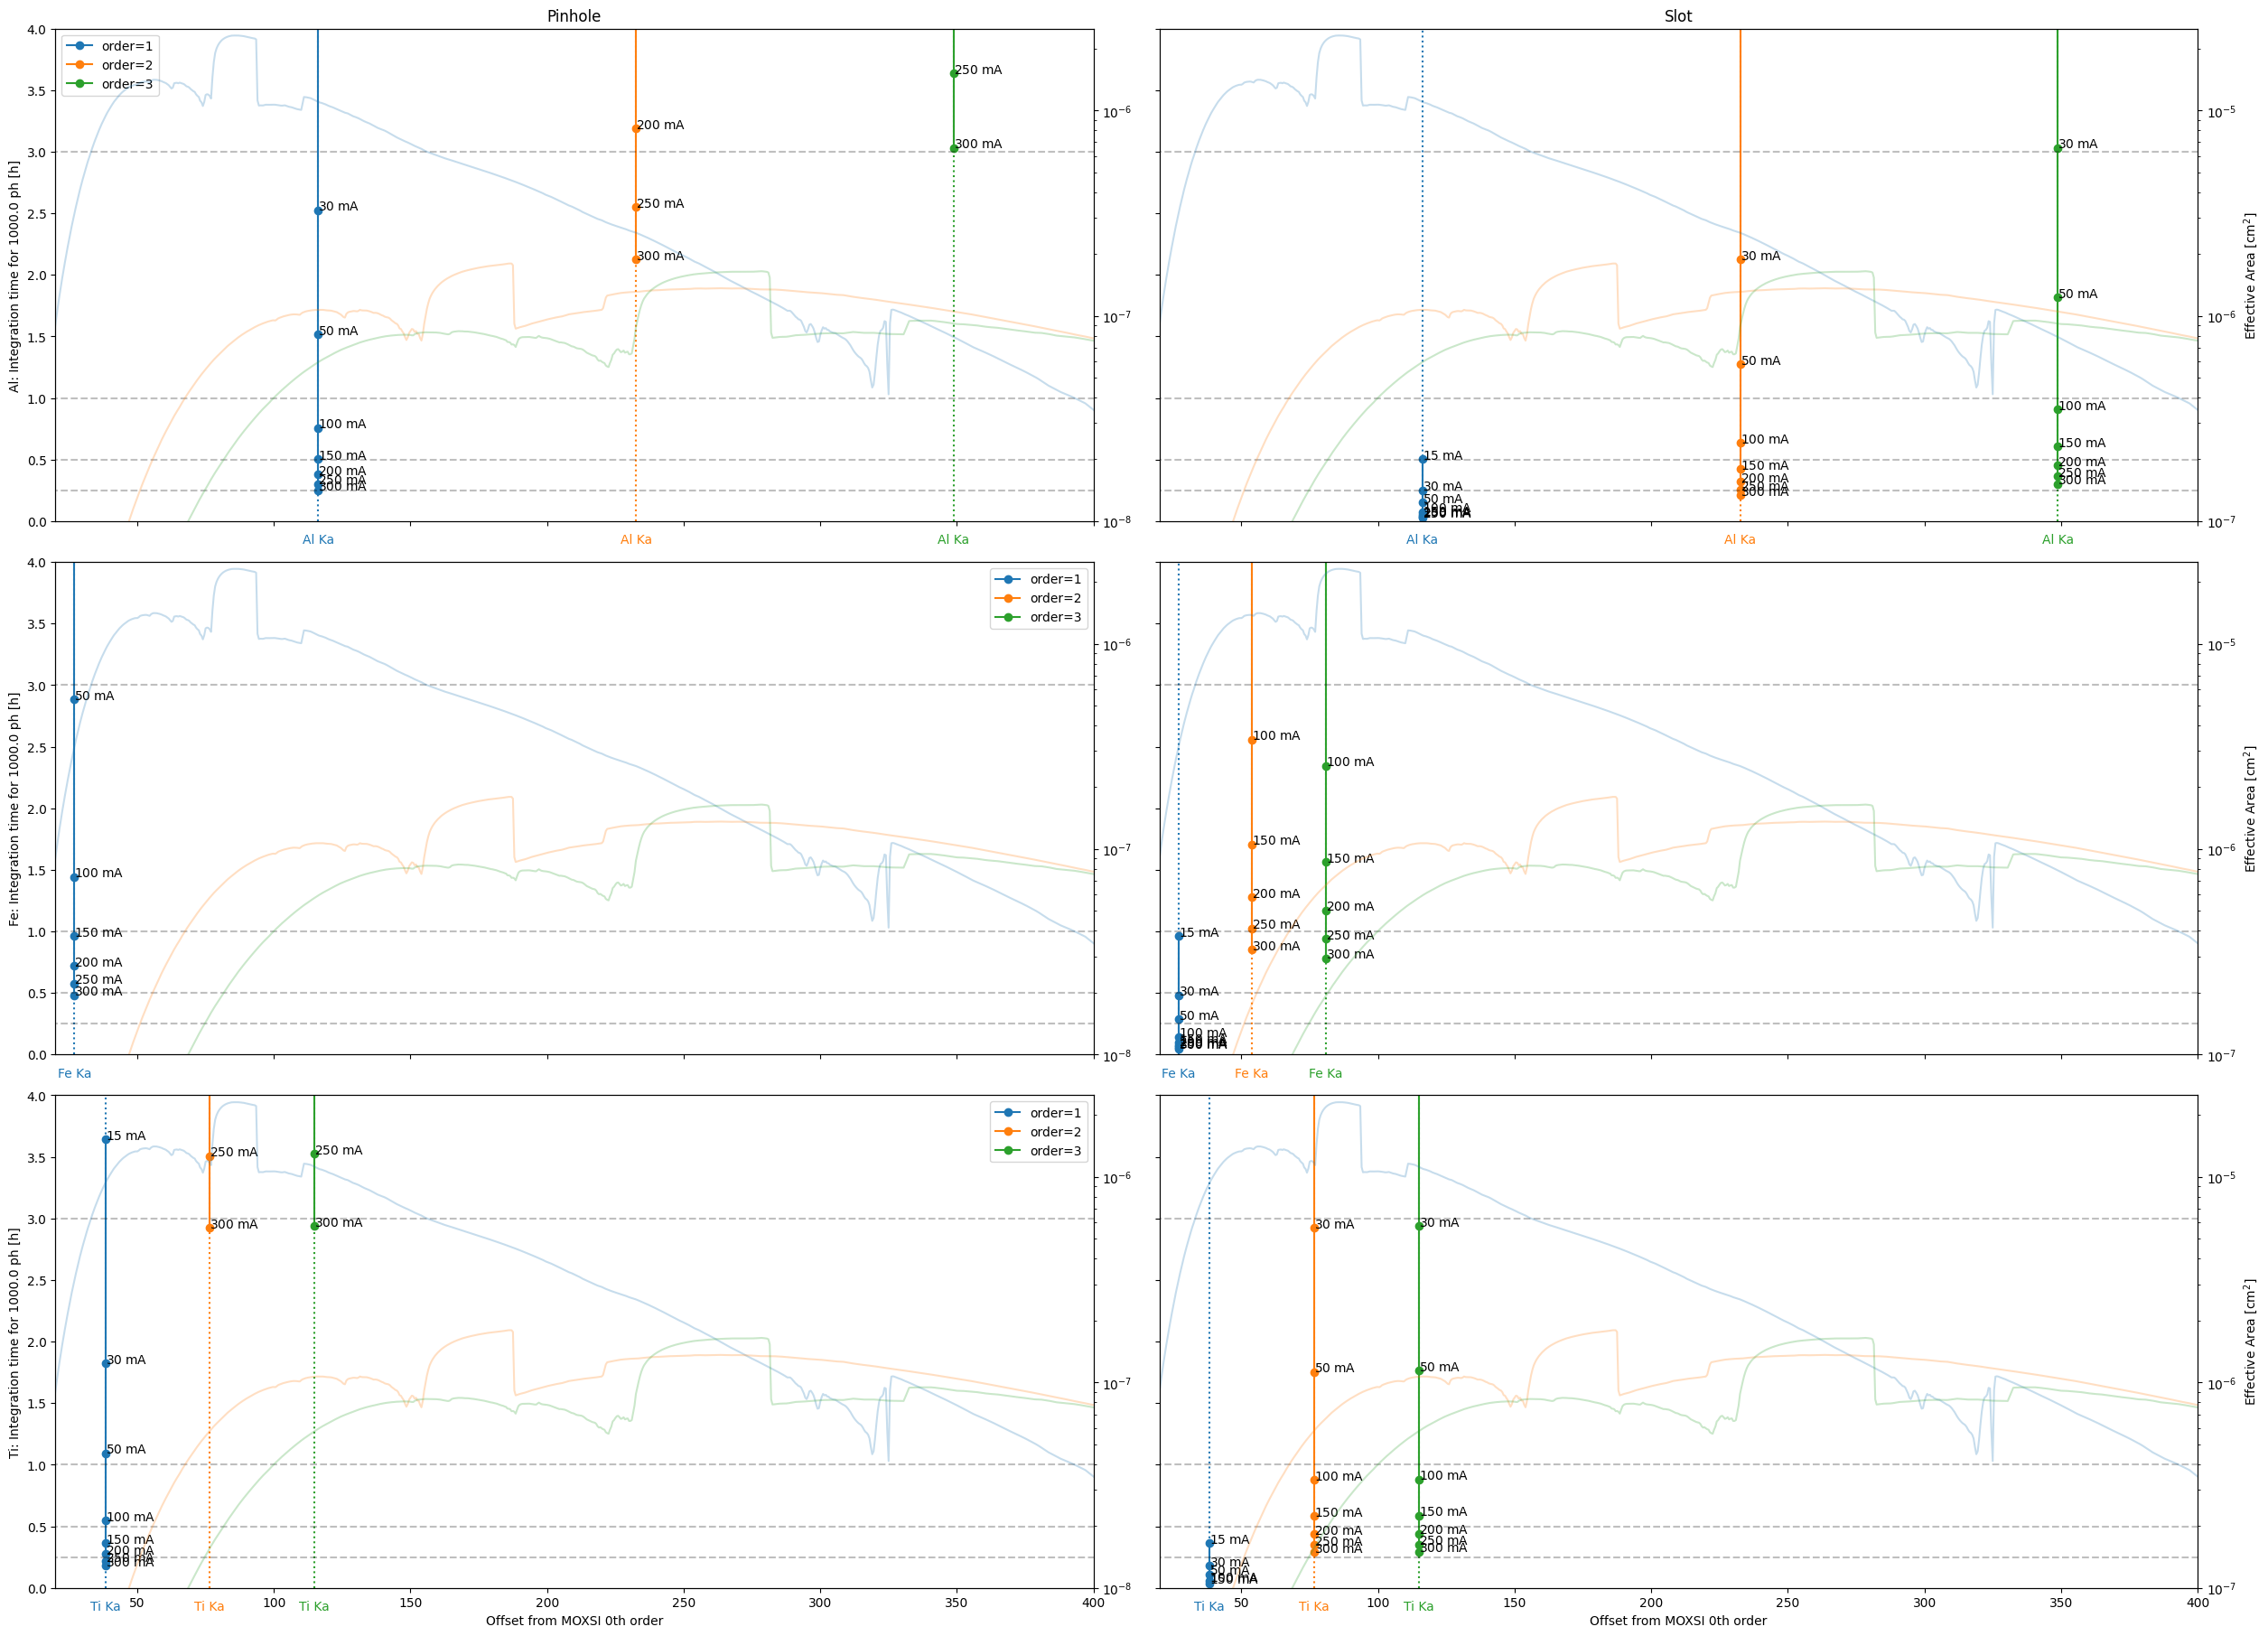

In [20]:
target_names = np.unique(integration_time_table['target'])
fig = plt.figure(figsize=(25,6*len(target_names)), layout='constrained')
upper_lim = 4 * u.h
for j,target in enumerate(target_names):
    _tab = integration_time_table[integration_time_table['target']==target]
    ax1 = fig.add_subplot(len(target_names), 2, 2*j+1)
    ax1t = ax1.twinx()
    for i,mr in enumerate(moxsi_responses[:3]):
        moxsi_wcs = mr.get_wcs(obs)
        colname = f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'
        pix_pos = moxsi_wcs.world_to_pixel(source_pos, _tab['wavelength'])
        for k,(p,it) in enumerate(zip(pix_pos[0], _tab[colname])):
            ax1.plot(len(it)*[p-px_0th,], it, '-o', color=f'C{i}', label=f'order={mr.spectral_order}' if k==0 else None)
            for c,x in zip(_tab['current'][k],it):
                if x<upper_lim:
                    ax1.text(p-px_0th, x.to_value('h'), f'{c:latex_inline}')
            if (it<upper_lim).any():
                ax1.axvline(x=p-px_0th, ls=':', color=f'C{i}')
                ax1.text(p-px_0th,-0.1, _tab['line'][k], color=f'C{i}', ha='center', va='top')
        if j == 0 and i == 0:
            ax1.set_title(mr.name.split('_')[1].capitalize())
        ax1t.plot(moxsi_wcs.world_to_pixel(source_pos, mr.wavelength)[0]-px_0th, mr.effective_area, color=f'C{i}', alpha=0.25)
    ax1.hlines([0.25,0.5,1,3,6,12.24],0,1500,colors='k', ls='--', alpha=0.25)
    ax2 = fig.add_subplot(len(target_names), 2, 2*(j+1), sharey=ax1, sharex=ax1)
    ax2t = ax2.twinx()
    for i,mr in enumerate(moxsi_responses[3:]):
        moxsi_wcs = mr.get_wcs(obs)
        colname = f'moxsi_{mr.name.split('_')[1]}_{mr.spectral_order}'
        pix_pos = moxsi_wcs.world_to_pixel(source_pos, _tab['wavelength'])
        for k,(p,it) in enumerate(zip(pix_pos[0], _tab[colname])):
            ax2.plot(len(it)*[p-px_0th,], it, '-o', color=f'C{i}', label=f'order={mr.spectral_order}' if k==0 else None)
            for c,x in zip(_tab['current'][k],it):
                if x<upper_lim:
                    ax2.text(p-px_0th, x.to_value('h'), f'{c:latex_inline}')
            if (it<upper_lim).any():
                ax2.axvline(x=p-px_0th, ls=':', color=f'C{i}')
                ax2.text(p-px_0th,-0.1, _tab['line'][k], color=f'C{i}', ha='center', va='top')
        if j == 0 and i == 0:
            ax2.set_title(mr.name.split('_')[1].capitalize())
        ax2t.plot(moxsi_wcs.world_to_pixel(source_pos, mr.wavelength)[0]-px_0th, mr.effective_area, color=f'C{i}', alpha=0.25)
    ax2.hlines([0.25,0.5,1,3,6,12.24],0,1500,colors='k', ls='--', alpha=0.25)
    # Labels
    ax1.legend()
    ax1.set_ylim(0,upper_lim.to_value('h'))
    ax1.set_xlim(20,400)
    ax1.set_xlabel('Offset from MOXSI 0th order')
    ax2.set_xlabel('Offset from MOXSI 0th order')
    ax1.set_ylabel(f'{target}: Integration time for {photon_threshold} [h]')
    ax1t.set_yscale('log')
    ax2t.set_yscale('log')
    ax1t.set_ylim(1e-8, 2.5e-6)
    ax2t.set_ylim(1e-7, 2.5e-5)
    ax2t.set_ylabel('Effective Area [cm$^2$]')
    ax1.label_outer()
    ax2.label_outer()
fig.savefig('figures/integration-time-summary-major-lines.pdf', bbox_inches='tight', transparent=True, dpi=300)

## Sandbox